In [4]:
from google.colab import files

uploaded = files.upload()

Saving dataset.zip to dataset (1).zip


In [7]:
import os

for root, dirs, files in os.walk("/content/Food5K"):
    print("Folder:", root)
    print("Subfolders:", dirs)
    print("Images:", len([
        f for f in files
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]))
    print("-" * 40)

    if root.count(os.sep) >= 5:
        dirs[:] = []

Folder: /content/Food5K
Subfolders: ['training']
Images: 0
----------------------------------------
Folder: /content/Food5K/training
Subfolders: ['food']
Images: 0
----------------------------------------
Folder: /content/Food5K/training/food
Subfolders: []
Images: 0
----------------------------------------


In [8]:
import os

dataset_path = "/content/Food5K"

for root, dirs, files in os.walk(dataset_path):
    if {"training", "validation", "evaluation"}.issubset(set(dirs)):
        dataset_path = root
        break

print("Correct dataset path:", dataset_path)
print("Folders:", os.listdir(dataset_path))

Correct dataset path: /content/Food5K
Folders: ['training']


In [10]:
import zipfile

zip_path = "/content/dataset (1).zip"

with zipfile.ZipFile(zip_path, "r") as z:
    for name in z.namelist()[:40]:
        print(name)

training/
training/food/
training/food/0.jpg
training/food/1.jpg
training/food/10.jpg
training/food/100.jpg
training/food/1000.jpg
training/food/1001.jpg
training/food/1002.jpg
training/food/1003.jpg
training/food/1004.jpg
training/food/1005.jpg
training/food/1006.jpg
training/food/1007.jpg
training/food/1008.jpg
training/food/1009.jpg
training/food/101.jpg
training/food/1010.jpg
training/food/1011.jpg
training/food/1012.jpg
training/food/1013.jpg
training/food/1014.jpg
training/food/1015.jpg
training/food/1016.jpg
training/food/1017.jpg
training/food/1018.jpg
training/food/1019.jpg
training/food/102.jpg
training/food/1020.jpg
training/food/1021.jpg
training/food/1022.jpg
training/food/1023.jpg
training/food/1024.jpg
training/food/1025.jpg
training/food/1026.jpg
training/food/1027.jpg
training/food/1028.jpg
training/food/1029.jpg
training/food/103.jpg
training/food/1030.jpg


In [11]:
import os

for root, dirs, files in os.walk("/content/Food5K"):
    print("\nFolder:", root)
    print("Subfolders:", dirs)
    print("Files:", files[:5])

    if root.count(os.sep) > 5:
        dirs[:] = []


Folder: /content/Food5K
Subfolders: ['training']
Files: []

Folder: /content/Food5K/training
Subfolders: ['food']
Files: []

Folder: /content/Food5K/training/food
Subfolders: []
Files: []


In [12]:
from collections import Counter

counts = Counter()

for root, dirs, files in os.walk("/content/Food5K"):
    for file in files:
        if file.lower().endswith((".jpg", ".jpeg", ".png")):
            counts[root] += 1

for folder, count in counts.items():
    print(folder, ":", count)

In [13]:
import os
import zipfile
import shutil

zip_path = "/content/dataset (1).zip"
extract_path = "/content/Food5K"


if os.path.exists(extract_path):
    shutil.rmtree(extract_path)

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(extract_path)

print("Extraction completed!")

Extraction completed!


In [14]:
for split in ["training", "validation", "evaluation"]:

    folder = os.path.join(extract_path, split)

    print("\n", split)

    if os.path.exists(folder):
        print("Subfolders:", os.listdir(folder))

        for category in os.listdir(folder):
            category_path = os.path.join(folder, category)

            if os.path.isdir(category_path):
                print(
                    category,
                    ":",
                    len(os.listdir(category_path)),
                    "images"
                )
    else:
        print("Folder not found")


 training
Subfolders: ['food', 'non_food']
food : 1500 images
non_food : 1500 images

 validation
Subfolders: ['food', 'non_food']
food : 500 images
non_food : 500 images

 evaluation
Subfolders: ['food', 'non_food']
food : 500 images
non_food : 500 images


In [15]:
import tensorflow as tf
import os

DATASET_PATH = "/content/Food5K"

IMG_SIZE = (160, 160)
BATCH_SIZE = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(DATASET_PATH, "training"),
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    class_names=["non_food", "food"],
    shuffle=True,
    seed=42
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(DATASET_PATH, "validation"),
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    class_names=["non_food", "food"],
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(DATASET_PATH, "evaluation"),
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    class_names=["non_food", "food"],
    shuffle=False
)

print("Classes:", train_ds.class_names)

Found 3000 files belonging to 2 classes.
Found 1000 files belonging to 2 classes.
Found 1000 files belonging to 2 classes.
Classes: ['non_food', 'food']


In [16]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

In [17]:
from tensorflow.keras import layers

augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1)
])

In [18]:
from tensorflow.keras.applications import MobileNetV2

base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(160, 160, 3)
)

base_model.trainable = False

inputs = layers.Input(shape=(160, 160, 3))

x = augmentation(inputs)

x = layers.Rescaling(
    scale=1./127.5,
    offset=-1
)(x)

x = base_model(x, training=False)

x = layers.GlobalAveragePooling2D()(x)

x = layers.Dropout(0.3)(x)

outputs = layers.Dense(1, activation="sigmoid")(x)

model = tf.keras.Model(inputs, outputs)

print("MobileNetV2 model ready!")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
MobileNetV2 model ready!


In [19]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [20]:
callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        "/content/best_food5k.keras",
        monitor="val_accuracy",
        save_best_only=True,
        mode="max"
    ),

    tf.keras.callbacks.ModelCheckpoint(
        "/content/latest_food5k.keras",
        save_best_only=False
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2
    )
]

In [22]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    callbacks=callbacks
)

Epoch 1/5
94/94 ━━━━━━━━━━━━━━━━━━━━ 51s 541ms/step - accuracy: 0.9793 - loss: 0.0554 - val_accuracy: 0.9820 - val_loss: 0.0632 - learning_rate: 0.0010
Epoch 2/5
94/94 ━━━━━━━━━━━━━━━━━━━━ 61s 655ms/step - accuracy: 0.9813 - loss: 0.0557 - val_accuracy: 0.9810 - val_loss: 0.0596 - learning_rate: 0.0010
Epoch 3/5
94/94 ━━━━━━━━━━━━━━━━━━━━ 73s 552ms/step - accuracy: 0.9847 - loss: 0.0496 - val_accuracy: 0.9840 - val_loss: 0.0589 - learning_rate: 0.0010
Epoch 4/5
94/94 ━━━━━━━━━━━━━━━━━━━━ 81s 542ms/step - accuracy: 0.9840 - loss: 0.0496 - val_accuracy: 0.9850 - val_loss: 0.0589 - learning_rate: 0.0010
Epoch 5/5
94/94 ━━━━━━━━━━━━━━━━━━━━ 63s 673ms/step - accuracy: 0.9813 - loss: 0.0525 - val_accuracy: 0.9850 - val_loss: 0.0587 - learning_rate: 0.0010


In [23]:
best_model = tf.keras.models.load_model(
    "/content/best_food5k.keras"
)

loss, accuracy = best_model.evaluate(test_ds)

print("Test Loss:", round(loss, 4))
print("Test Accuracy:", round(accuracy * 100, 2), "%")

32/32 ━━━━━━━━━━━━━━━━━━━━ 13s 356ms/step - accuracy: 0.9850 - loss: 0.0433
Test Loss: 0.0433
Test Accuracy: 98.5 %


In [24]:
best_model.save("/content/food_recognition_model.keras")

print("Final model saved successfully!")

Final model saved successfully!


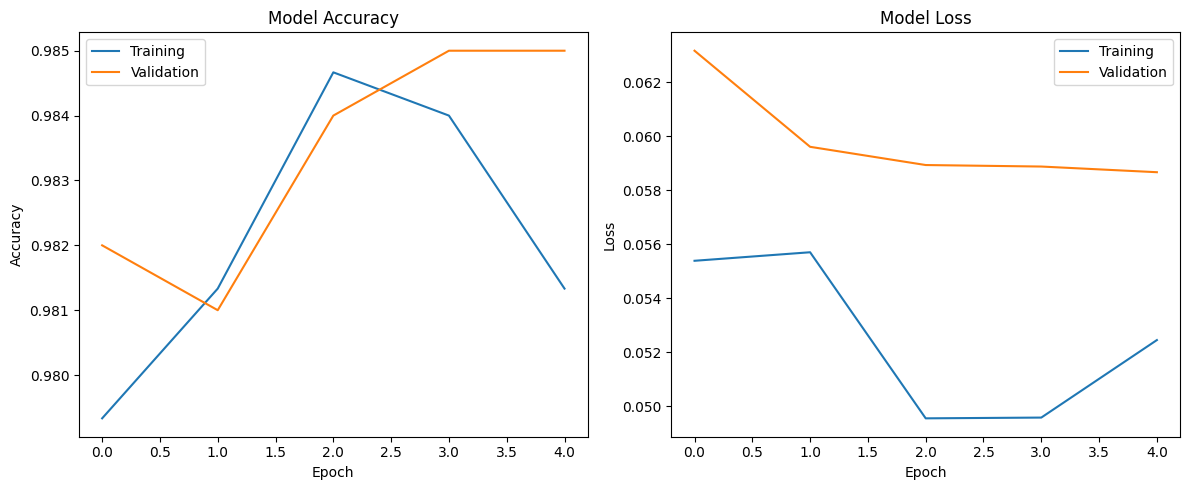

In [26]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [27]:
plt.savefig(
    "/content/food5k_training_graph.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

<Figure size 640x480 with 0 Axes>

In [28]:
from google.colab import files

files.download("/content/food5k_training_graph.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>